<a href="https://colab.research.google.com/github/Moon-JB/26-2-DIP-202201276/blob/main/hw05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.ndimage as nd
from PIL import Image

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/DIP4E/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. object counting에 사용할 image를 grayscale로 불러오기

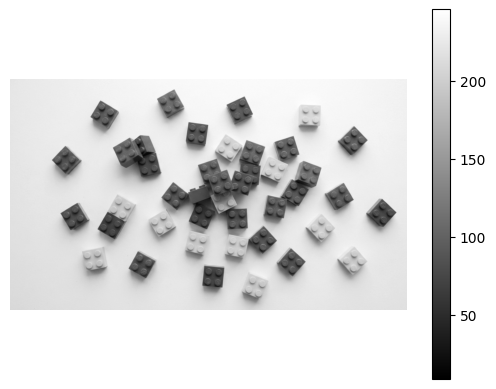

In [ ]:
I = Image.open(imgpath+'/lego.png').convert('L')
f = np.array(I)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 2. 적절한 전처리를 통해 영상의 noise를 줄이기

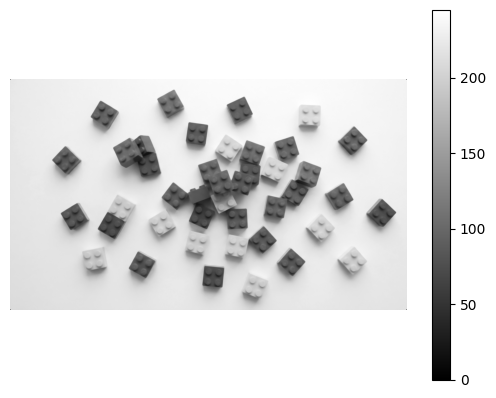

In [ ]:
f_denoised = signal.medfilt2d(f,5)
plt.imshow(f_denoised,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기

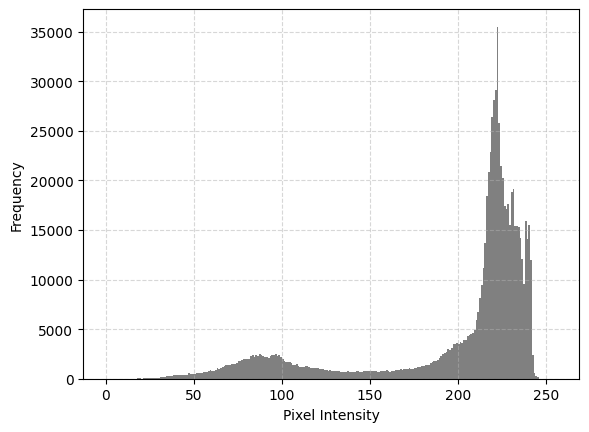

In [ ]:
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

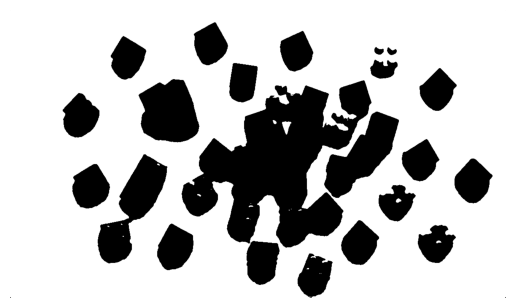

In [ ]:
th_val = 203
f_mask = f_denoised > th_val
plt.imshow(f_mask,cmap='gray')
plt.axis('off')
plt.show()

## 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기

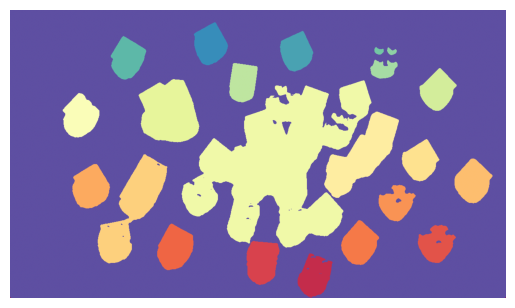

In [ ]:
labels, nums = nd.label(f_mask == 0)
plt.imshow(labels,cmap='Spectral_r')
plt.axis('off')
plt.show()

In [ ]:
cc = np.zeros((nums,2))
for i in range(1,nums + 1):
  cc[i-1,0] = i
  cc[i-1,1] = np.sum(labels==i)
  print(f'index: {int(cc[i-1,0])}, number of pixels: {int(cc[i-1,1])}')

index: 1, number of pixels: 3
index: 2, number of pixels: 3
index: 3, number of pixels: 5660
index: 4, number of pixels: 5290
index: 5, number of pixels: 5744
index: 6, number of pixels: 271
index: 7, number of pixels: 257
index: 8, number of pixels: 2002
index: 9, number of pixels: 5058
index: 10, number of pixels: 5570
index: 11, number of pixels: 16219
index: 12, number of pixels: 85340
index: 13, number of pixels: 6313
index: 14, number of pixels: 2
index: 15, number of pixels: 16505
index: 16, number of pixels: 5755
index: 17, number of pixels: 17452
index: 18, number of pixels: 6348
index: 19, number of pixels: 6742
index: 20, number of pixels: 4711
index: 21, number of pixels: 6281
index: 22, number of pixels: 6700
index: 23, number of pixels: 5258
index: 24, number of pixels: 6492
index: 25, number of pixels: 5732
index: 26, number of pixels: 3
index: 27, number of pixels: 3


## 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기

In [ ]:
sizes = np.bincount(labels.ravel())
sizes[0] = 0
ind_max = np.argmax(sizes)
print(f'the largest component: index {int(ind_max)}, # of pixels: {int(cc[ind_max,1])}')
ind_min = np.argmin(sizes[1:]) + 1
print(f'the smallest component: index {int(ind_min)}, # of pixels: {int(cc[ind_min,1])}')

the largest component: index 12, # of pixels: 6313
the smallest component: index 14, # of pixels: 16505


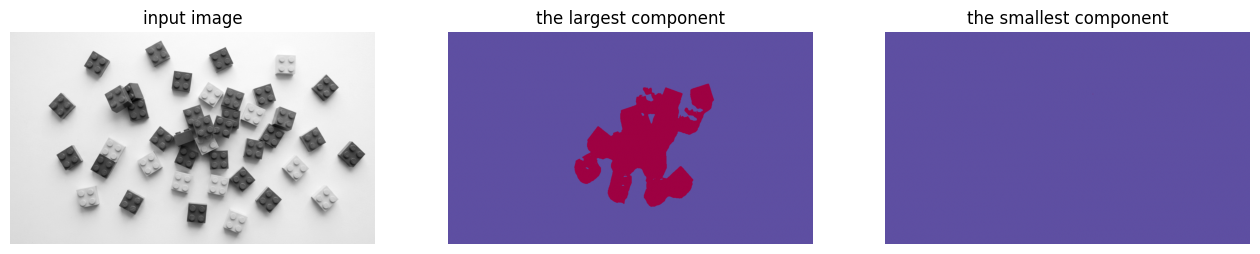

In [ ]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('input image')
plt.subplot(132)
plt.imshow(labels==ind_max,cmap='Spectral_r')
plt.axis('off')
plt.title('the largest component')
plt.subplot(133)
plt.imshow(labels==ind_min, cmap='Spectral_r')
plt.axis('off')
plt.title('the smallest component')
plt.show()